In [1]:
import mdtraj as md
import numpy as np
import matplotlib.pyplot as plt
import os
import pickle


N_TIMESTEP_IN_REPLICA_CMD  = 18000
N_TIMESTEP_IN_REPLICA_PACS = 101
TEMPERATURE = 300

pickle_dir = "./pickle-cache/pca_tetranucl"
if not os.path.exists(pickle_dir):
    os.mkdir(pickle_dir)

gleap_target = md.load("../20250801_FUS-RRM/2_md-preparation-2/gleap.target.gro")
atom_indices_protein = gleap_target.topology.select("resid 23 to 126")
atom_indices_rna     = gleap_target.topology.select("resid  0 to  22")


atom_pairs_gleap = []
for protein_atom in [atom for atom in gleap_target.topology.atoms if atom.name.startswith("CA") and 24<=atom.residue.index<=125][::3]:
    c_rna = [atom for atom in gleap_target.topology.atoms if atom.name.startswith("C") and 11<=atom.residue.index<=14]
    for rna_atom in sorted(c_rna, key=lambda atom: (atom.name, atom.index)):
        atom_pairs_gleap.append((protein_atom.index, rna_atom.index))
print(len(atom_pairs_gleap))

distances = {}
distances["cmd"] = []
for trial in range(5):
    xtc = md.load(f"../20250801_FUS-RRM/6_cmd-{trial+1}/cmd.skip10.whole.target.pbc.xtc", top=gleap_target)[2001:]
    print(trial, xtc.n_frames)
    _distances = md.compute_distances(xtc, atom_pairs_gleap)
    distances["cmd"].append(_distances)


distances["pacs"] = []
for trial in range(50):
    xtc = md.load(f"../20250801_FUS-RRM/7_pacs-1/trial{trial+1:03}/prd.target.trjcat-all.pbc.2.2nm.xtc", top=gleap_target)
    print(trial, xtc.n_frames)
    _distances = md.compute_distances(xtc, atom_pairs_gleap).reshape(-1, N_TIMESTEP_IN_REPLICA_PACS, len(atom_pairs_gleap))
    distances["pacs"].append(_distances)


pdbs_nmr = md.load("../20250801_FUS-RRM/1_modelling/1_6gbm.pdb")
atom_pairs_nmr = []
for protein_atom in [atom for atom in pdbs_nmr.topology.atoms if atom.name.startswith("CA") and 0<=atom.residue.index<=101][::3]:
    c_rna = [atom for atom in pdbs_nmr.topology.atoms if atom.name.startswith("C") and 113<=atom.residue.index<=116]
    for rna_atom in sorted(c_rna, key=lambda atom: (atom.name, atom.index)):
        atom_pairs_nmr.append((protein_atom.index, rna_atom.index))
print(len(atom_pairs_nmr))
distances["nmr"]  = md.compute_distances(pdbs_nmr, atom_pairs_nmr)

1258
0 18000
1 18000
2 18000
3 18000
4 18000
0 101909
1 126048
2 108979
3 121402
4 208868
5 147359
6 209272
7 121402
8 443390
9 175033
10 129179
11 85244
12 116554
13 296233
14 182204
15 128371
16 102111
17 139784
18 93223
19 34138
20 113827
21 111807
22 81305
23 73831
24 93627
25 76659
26 160186
27 92819
28 165842
29 117463
30 111302
31 46056
32 85446
33 56055
34 12625
35 77467
36 64236
37 132815
38 141198
39 182911
40 60903
41 97061
42 112413
43 71912
44 63226
45 205333
46 194829
47 112817
48 142107
49 203212


/work18/kijima/programs/anaconda3/envs/jupyter/lib/python3.10/site-packages/mdtraj/formats/pdb/pdbfile.py:206: UserWarning: Unlikely unit cell vectors detected in PDB file likely resulting from a dummy CRYST1 record. Discarding unit cell vectors.
  warnings.warn(


1258


In [2]:
import sklearn.decomposition


if False:
    pca = sklearn.decomposition.PCA(n_components=2, svd_solver="full")
    pca.fit(np.concatenate(distances["cmd"])[::10])
    pickle.dump(pca, open(f"{pickle_dir}/pca.pickle", "wb"))

pca = pickle.load(open(f"{pickle_dir}/pca.pickle", "rb"))
print(pca.explained_variance_ratio_)

trajs = [pca.transform(_distances) for _distances in distances["cmd"]]

[0.2992402  0.23307948]


In [3]:
from sklearn.cluster import KMeans
import matplotlib


def cluster_trajs(trajs, n_clusters):
    clustering_model = KMeans(
        n_clusters=n_clusters,
        init="k-means++",
        n_init=10,
        max_iter=int(1e10),
        tol=1e-10,
        verbose=0,
        random_state=1,
        copy_x=True,
        algorithm="lloyd"
    )
    trajs_concat = np.concatenate(trajs)
    clustered_trajs_concat = clustering_model.fit_predict(trajs_concat)
    return clustered_trajs_concat.reshape(len(trajs), N_TIMESTEP_IN_REPLICA_CMD), clustering_model.cluster_centers_


def plot_clusters(ax, trajs, clustered_trajs, cluster_centers):
    trajs_concat = np.concatenate(trajs)
    clustered_trajs_concat = np.concatenate(clustered_trajs)

    ax.scatter(trajs_concat[:, 0], trajs_concat[:, 1], s=0.1, c=[matplotlib.cm.tab20(i_cluster%20) for i_cluster in clustered_trajs_concat])
    for cluster_center in cluster_centers:
        ax.scatter(cluster_center[0], cluster_center[1], color="black", s=5)

    ax.grid(True, color="black", alpha=0.3)
    ax.set_aspect("equal", adjustable="box")

In [4]:
from deeptime.markov import TransitionCountEstimator
from deeptime.markov.msm import MaximumLikelihoodMSM
from deeptime.markov.tools import estimation
from deeptime.util.validation import implied_timescales
import deeptime.plots


def construct_msm(clustered_trajs, lagtimes):
    msm_models = {}
    stationary_distributions = {}

    for lagtime in lagtimes:
        count_estimator = TransitionCountEstimator(
            lagtime=lagtime,
            count_mode="sliding",
            n_states=None,
            sparse=False,
        )
        count_estimator.fit(clustered_trajs)
        count_model = count_estimator.fetch_model()

        msm_constructor = MaximumLikelihoodMSM(
            reversible=True,
            stationary_distribution_constraint=None,
            sparse=False,
            allow_disconnected=False,
            maxiter=int(1e10),
            maxerr=1e-10,
            connectivity_threshold=0,
            transition_matrix_tolerance=1e-10,
            lagtime=None,
            use_lcc=False,
        ) 

        try:
            msm_constructor.fit(count_model)
        except:
            continue

        msm_models[lagtime] = msm_constructor.fetch_model()
        largest_connected_set = estimation.largest_connected_set(count_model.count_matrix, directed=True)
        stationary_distributions[lagtime] = np.zeros(np.max(clustered_trajs)+1)
        stationary_distributions[lagtime][largest_connected_set] = msm_models[lagtime].stationary_distribution

    return msm_models, stationary_distributions


def plot_implied_timescales(ax, msm_models):
    deeptime.plots.plot_implied_timescales(
        implied_timescales(list(msm_models.values())),
        n_its=10,
        ax=ax,
        process=None,
        show_mle=True,
        show_sample_mean=True,
        show_sample_confidence=True,
        show_cutoff=True,
        sample_confidence=0.95,
        colors=None,
    )
    ax.set_xlim(0, np.max(list(msm_models.keys())))
    ax.set_yscale("log")

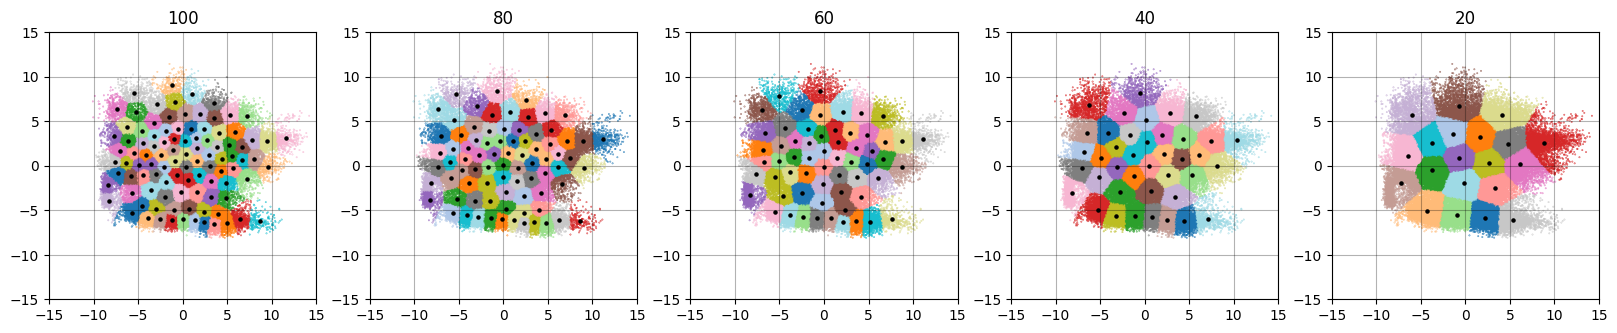

In [5]:
n_clusters_candidates = [100, 80, 60, 40, 20]

fig_cluster, ax_cluster = plt.subplots(1, len(n_clusters_candidates))
fig_cluster.set_size_inches(4*len(n_clusters_candidates), 4)

if False:
    clustered_trajs = {}
    cluster_centers = {}
    for i_clusters, n_clusters in enumerate(n_clusters_candidates):
        print(n_clusters)
        clustered_trajs[n_clusters], cluster_centers[n_clusters] = cluster_trajs(trajs, n_clusters)
    pickle.dump(clustered_trajs, open(f"{pickle_dir}/clustered_trajs.pickle", "wb"))
    pickle.dump(cluster_centers, open(f"{pickle_dir}/cluster_centers.pickle", "wb"))

clustered_trajs = pickle.load(open(f"{pickle_dir}/clustered_trajs.pickle", "rb"))
cluster_centers = pickle.load(open(f"{pickle_dir}/cluster_centers.pickle", "rb"))


for i_clusters, n_clusters in enumerate(n_clusters_candidates):
    plot_clusters(ax_cluster[i_clusters], trajs, clustered_trajs[n_clusters], cluster_centers[n_clusters])
    ax_cluster[i_clusters].set_title(n_clusters)
    ax_cluster[i_clusters].set_xlim(-15, 15)
    ax_cluster[i_clusters].set_ylim(-15, 15)
    ax_cluster[i_clusters].set_xticks(range(-15, 16, 5))
    ax_cluster[i_clusters].set_yticks(range(-15, 16, 5))

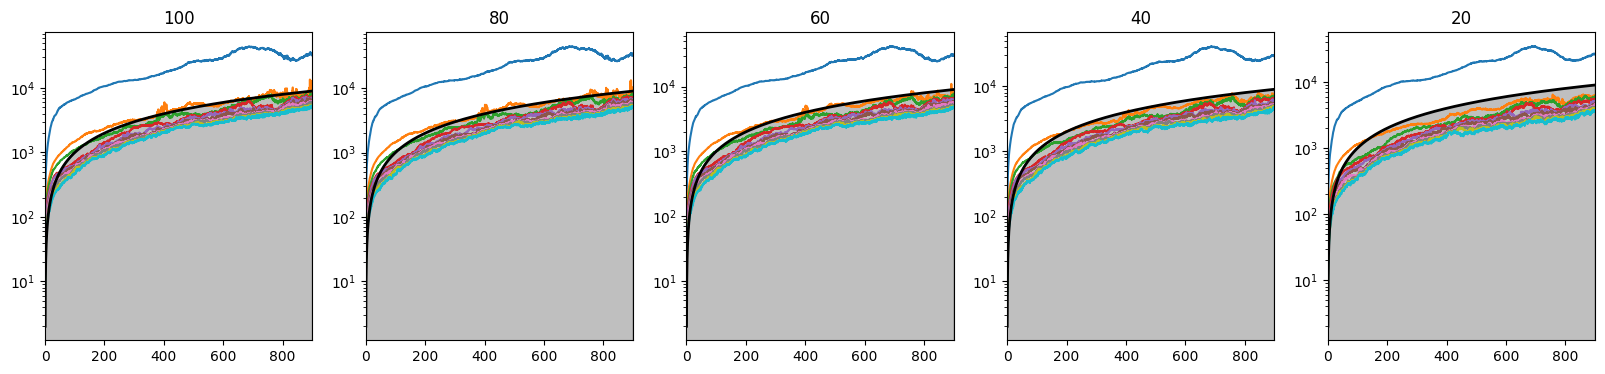

In [6]:
fig_its, ax_its = plt.subplots(1, len(n_clusters_candidates))
fig_its.set_size_inches(4*len(n_clusters_candidates), 4)

if False:
    msm_models = {}
    for i_clusters, n_clusters in enumerate(n_clusters_candidates):
        print(n_clusters)
        msm_models[n_clusters], _ = construct_msm(clustered_trajs[n_clusters], range(2, int(N_TIMESTEP_IN_REPLICA_CMD/2), 2))
    pickle.dump(msm_models , open(f"{pickle_dir}/msm_models.pickle" , "wb"))

msm_models = pickle.load(open(f"{pickle_dir}/msm_models.pickle" , "rb"))
        

for i_clusters, n_clusters in enumerate(n_clusters_candidates):
    plot_implied_timescales(ax_its[i_clusters], msm_models[n_clusters])
    ax_its[i_clusters].set_title(n_clusters)
    ax_its[i_clusters].set_xticks(range(0, 8001, 2000), range(0, 801, 200))

In [7]:
import scipy.constants
from deeptime.util import energy2d
from scipy.spatial import Voronoi


def plot_energy_landscape(ax, msm_model, trajs, clustered_trajs):
    kbt = scipy.constants.Boltzmann
    kbt *= TEMPERATURE
    kbt *= scipy.constants.Avogadro
    kbt /= scipy.constants.calorie
    kbt /= 1000
    
    weights = msm_model.compute_trajectory_weights(np.concatenate(clustered_trajs))[0]
    energies = energy2d(*np.concatenate(trajs).T, bins=(50, 50), kbt=kbt, weights=weights, shift_energy=True)
    
    ax, contour, cbar = energies.plot(contourf_kws=dict(cmap="nipy_spectral"), ax=ax)
    ax.grid(True, color="black", alpha=0.3)
    ax.set_aspect("equal", adjustable="box")

    return energies, cbar


def compute_metastable_states(msm_model, n_metastable_sets, trajs_concat, clustered_trajs_concat):
    pcca = msm_model.pcca(n_metastable_sets=n_metastable_sets)

    metastabled_trajs_concat = np.zeros(len(clustered_trajs_concat))
    for timestep, cluster_index in enumerate(clustered_trajs_concat):
        metastabled_trajs_concat[timestep] = np.argmax(pcca.memberships[cluster_index])

    boundary_lines = []
    voronoi = Voronoi(trajs_concat)
    for (p1, p2), ridge_vertices in zip(voronoi.ridge_points, voronoi.ridge_vertices):
        if -1 in ridge_vertices:
            continue
        if metastabled_trajs_concat[p1] != metastabled_trajs_concat[p2]:
            v0, v1 = voronoi.vertices[ridge_vertices]
            boundary_lines.append(((v0[0], v1[0]), (v0[1], v1[1])))

    return pcca, metastabled_trajs_concat, boundary_lines


def plot_metastable_states(ax, trajs_concat, metastabled_trajs_concat, color_sequence=None):
    colors = [matplotlib.cm.tab10(int(metastable_state_index)%10) for metastable_state_index in metastabled_trajs_concat]
    if color_sequence != None:
        colors = [color_sequence[int(metastable_state_index)] for metastable_state_index in metastabled_trajs_concat]
    ax.scatter(*trajs_concat.T, color=colors, s=0.1)

    ax.grid(True, color="black", alpha=0.3)
    ax.set_aspect("equal", adjustable="box")


def plot_voronoi_boundary(ax, boundary_lines):
    for p1, p2 in boundary_lines:
        ax.plot(p1, p2, color="black", linewidth=1)

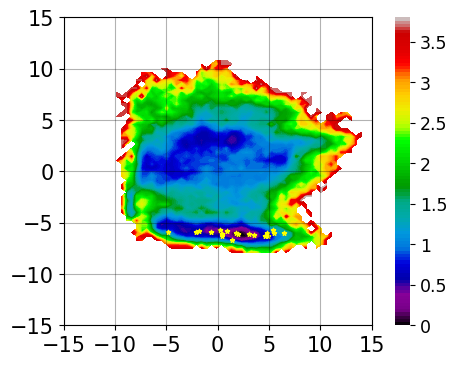

In [8]:
n_clusters = 60
lagtime = 1000

fig, ax = plt.subplots(1, 1)
fig.set_size_inches(6, 4)

energies, cbar = plot_energy_landscape(ax, msm_models[n_clusters][lagtime], trajs, clustered_trajs[n_clusters])
cbar.set_ticks(ticks=[0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5], labels=[0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5], size=12.5)
ax.scatter(*pca.transform(distances["nmr"]).transpose(1, 0), marker="*", s=10, color="yellow")

ax.set_xlim(-15, 15)
ax.set_ylim(-15, 15)

ax.set_xticks(range(-15, 16, 5))
ax.set_yticks(range(-15, 16, 5))

ax.tick_params(axis="x", labelsize=15)
ax.tick_params(axis="y", labelsize=15)

In [9]:
e_min_0 = 10000
e_min_1 = 10000

for i_x, x in enumerate(energies.x_meshgrid):
    for i_y, y in enumerate(energies.y_meshgrid):
        e = energies.energies[i_y, i_x]
        if y < 0 and e < e_min_0:
            e_min_0 = e
        elif y > 0 and e < e_min_1:
            e_min_1 = e

print(e_min_0, e_min_1)

0.0 0.47086448893476807


[[ 1.         -0.02914133]
 [-0.02914133  1.        ]]
-7.985313488605229


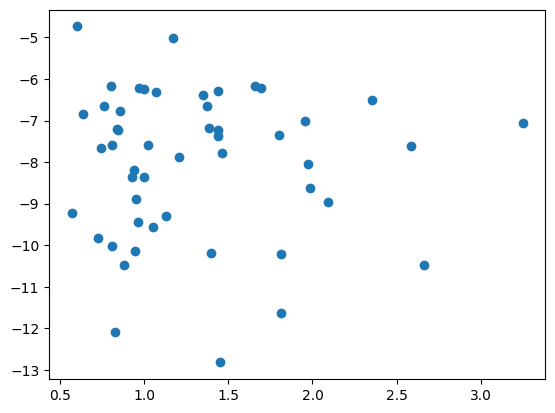

In [10]:
g_stds = np.array([ -6.21011302,  -8.35210496,  -7.2327437 ,  -7.5992825 ,
        -8.36345241,  -7.20380646,  -9.44766826,  -5.00322129,
       -10.02518348,  -6.25178025,  -6.65873979, -10.13089765,
        -9.22416801, -12.82381758, -10.21176401,  -7.17222673,
        -7.37870462,  -8.9514507 ,  -7.23379183,  -8.18048749,
        -9.56584585,  -7.58882361,  -6.76926359,  -6.84996047,
        -7.65822051,  -8.0446038 ,  -7.61695259,  -6.32451076,
        -9.30306933, -10.48809448,  -6.2163131 ,  -4.73585379,
        -6.50986791,  -6.17124558,  -6.65776636,  -8.62376698,
        -6.18016257,  -7.00256408,  -6.29637976,  -7.05484072,
        -6.38172276,  -7.34168571, -10.47228009,  -7.77215668,
        -9.82198603, -10.19334507, -12.08947939,  -7.86607704,
        -8.89710202, -11.64381751])

trajs_pacs = [np.array([pca.transform(_d) for _d in _distances]) for _distances in distances["pacs"]]

trial_energies = np.zeros(len(distances["pacs"]))
for trial in range(len(distances["pacs"])):
    pacs_mean_pca = np.concatenate(trajs_pacs[trial]).mean(axis=0)
    i_x = np.argmin(np.abs(energies.x_meshgrid - pacs_mean_pca[0]))
    i_y = np.argmin(np.abs(energies.y_meshgrid - pacs_mean_pca[1]))
    trial_energies[trial] = energies.energies[i_y, i_x]
plt.scatter(trial_energies, g_stds)

correlation_matrix = np.corrcoef(trial_energies[np.isfinite(trial_energies)], g_stds[np.isfinite(trial_energies)])
print(correlation_matrix)

trial_energies -= np.min(trial_energies)
weights = np.exp(-trial_energies / scipy.constants.Boltzmann / TEMPERATURE / scipy.constants.Avogadro * scipy.constants.calorie * 1000)
weights /= weights.sum()

tmp = g_stds * weights
reweighted_g_stds = tmp[np.isfinite(tmp)].sum()
print(reweighted_g_stds)

2
[[0.91181781 0.08818219]
 [0.05771891 0.94228109]]
[0.39560298 0.60439702]
17325.344452679692
11340.15855083948

3
[[0.57781144 0.21034349 0.21184507]
 [0.08092055 0.9074532  0.01162625]
 [0.09878204 0.04550436 0.8557136 ]]
[0.17129796 0.53415681 0.29454523]
10805.343803189657
11511.914796779809

4
[[ 5.38454720e-01  3.08587079e-01  1.83267227e-01 -3.03090259e-02]
 [ 1.33290961e-01  7.77498411e-01  7.63748547e-02  1.28357733e-02]
 [ 7.81798814e-02  4.15567674e-02  6.16383961e-01  2.63879390e-01]
 [ 1.87932398e-02  6.80528202e-05  2.03228445e-01  7.77910262e-01]]
[0.1314971  0.23676327 0.29065508 0.34108454]
17118.896093409217
9292.535561072747

5
[[ 0.47395044  0.31262365  0.01703253  0.18857602  0.00781737]
 [ 0.24109852  0.55414191  0.02557045  0.16319274  0.01599638]
 [-0.0058288  -0.026274    0.56313435  0.18478343  0.28418502]
 [ 0.15404032  0.15924736  0.07731115  0.59006447  0.0193367 ]
 [ 0.00680039 -0.00580603  0.15384903  0.0820431   0.7631135 ]]
[0.17458482 0.20714593 0.14

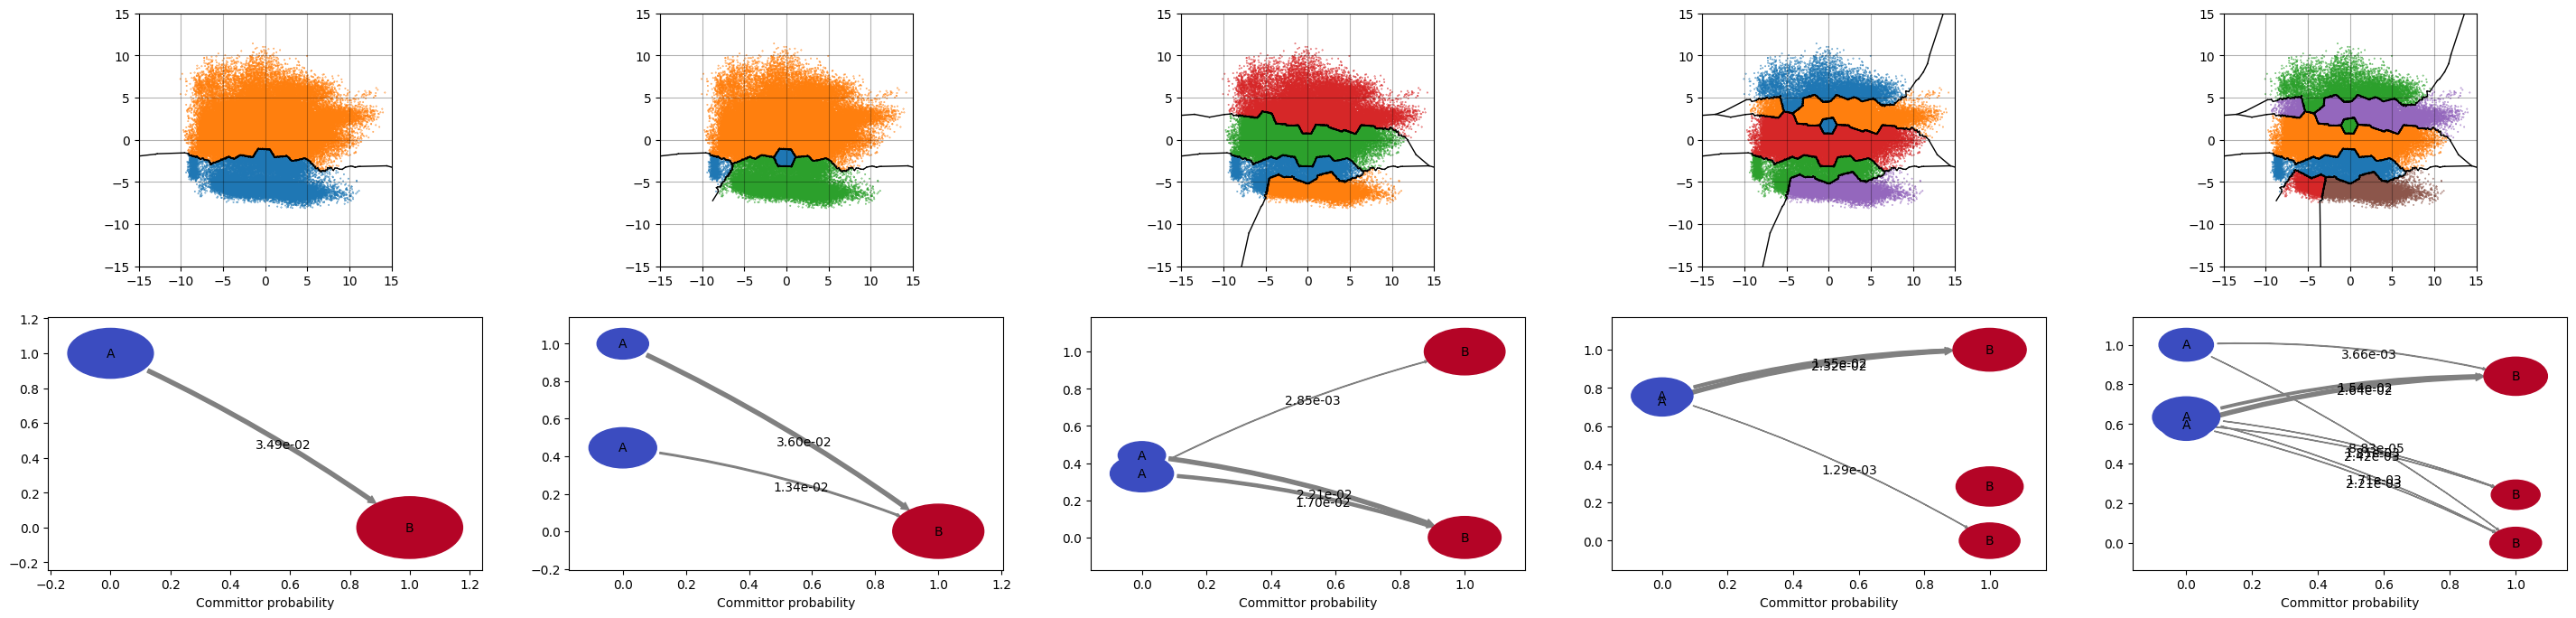

In [11]:
import os
from deeptime.markov.tools.analysis import mfpt


fig, ax = plt.subplots(2, 5)
fig.set_size_inches(36, 8)

metastate_0 = {
    2: [0],
    3: [0, 2],
    4: [0, 1],
    5: [2, 4],
    6: [0, 3, 5],
}
metastate_1 = {
    2: [1],
    3: [1],
    4: [2, 3],
    5: [0, 1, 3],
    6: [1, 2, 4],
}

for n_metastable_sets in range(2, 7):
    print(n_metastable_sets)
    pcca, metastabled_trajs_concat, boundary_lines = compute_metastable_states(msm_models[n_clusters][lagtime], n_metastable_sets, np.concatenate(trajs), np.concatenate(clustered_trajs[n_clusters]))
    pickle.dump(metastabled_trajs_concat, open(f"{pickle_dir}/metastabled_trajs_concat_{n_metastable_sets}.pickle", "wb"))
    pickle.dump(boundary_lines,           open(f"{pickle_dir}/boundary_lines_{n_metastable_sets}.pickle", "wb"))
    plot_metastable_states(ax[0, n_metastable_sets-2], np.concatenate(trajs), metastabled_trajs_concat)
    plot_voronoi_boundary(ax[0, n_metastable_sets-2], boundary_lines)

    print(pcca.coarse_grained_transition_matrix)
    print(pcca.coarse_grained_stationary_probability)
    print(mfpt(T=pcca.coarse_grained_transition_matrix, target=metastate_0[n_metastable_sets], origin=metastate_1[n_metastable_sets], tau=lagtime, mu=pcca.coarse_grained_stationary_probability))
    print(mfpt(T=pcca.coarse_grained_transition_matrix, target=metastate_1[n_metastable_sets], origin=metastate_0[n_metastable_sets], tau=lagtime, mu=pcca.coarse_grained_stationary_probability))
    print()

    ax[0, n_metastable_sets-2].set_xlim(-15, 15)
    ax[0, n_metastable_sets-2].set_ylim(-15, 15)

    ax[0, n_metastable_sets-2].set_xticks(range(-15, 16, 5))
    ax[0, n_metastable_sets-2].set_yticks(range(-15, 16, 5))


    transition_matrix = np.maximum(pcca.coarse_grained_transition_matrix, 0)
    transition_matrix /= transition_matrix.sum(axis=1, keepdims=True)

    flux = deeptime.markov.msm.MarkovStateModel(transition_matrix).reactive_flux(metastate_0[n_metastable_sets], metastate_1[n_metastable_sets])
    deeptime.plots.plot_flux(flux, ax=ax[1, n_metastable_sets-2])

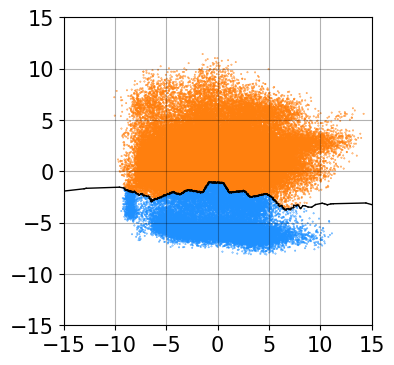

In [12]:
fig, ax = plt.subplots(1, 1)
fig.set_size_inches(4, 4)

metastabled_trajs_concat = pickle.load(open("./pickle-cache/pca_tetranucl/metastabled_trajs_concat_2.pickle", "rb"))
boundary_lines = pickle.load(open(f"./pickle-cache/pca_tetranucl/boundary_lines_2.pickle", "rb"))

plot_metastable_states(ax, np.concatenate(trajs), metastabled_trajs_concat, color_sequence=["#1E90FF", "tab:orange"])
plot_voronoi_boundary(ax, boundary_lines)

ax.set_xlim(-15, 15)
ax.set_ylim(-15, 15)

ax.set_xticks(range(-15, 16, 5))
ax.set_yticks(range(-15, 16, 5))

ax.tick_params(axis="x", labelsize=15)
ax.tick_params(axis="y", labelsize=15)

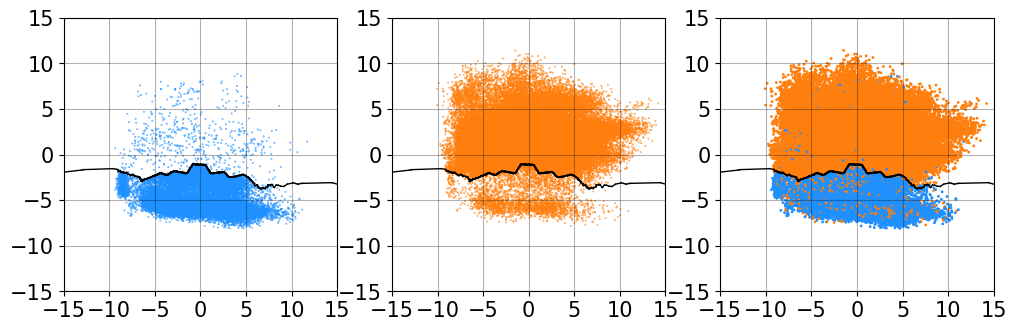

In [16]:
fig, ax = plt.subplots(1, 3)
fig.set_size_inches(12, 4)


metastabled_trajs_concat = pickle.load(open(f"./pickle-cache/sugar-puckering_classification/y_pred_adj_all.pickle", "rb"))

colors = ["#1E90FF", "tab:orange"]
trajs_concat = np.concatenate(trajs)
ax[0].scatter(trajs_concat[metastabled_trajs_concat==0, 0], trajs_concat[metastabled_trajs_concat==0, 1], c=[colors[state%2] for state in metastabled_trajs_concat if state==0], s=0.1)
ax[1].scatter(trajs_concat[metastabled_trajs_concat==1, 0], trajs_concat[metastabled_trajs_concat==1, 1], c=[colors[state%2] for state in metastabled_trajs_concat if state==1], s=0.1)
ax[2].scatter(trajs_concat[:, 0], trajs_concat[:, 1], c=[colors[state%2] for state in metastabled_trajs_concat], s=1)

_, _, boundary_lines = compute_metastable_states(msm_models[n_clusters][lagtime], 2, np.concatenate(trajs), np.concatenate(clustered_trajs[n_clusters]))
plot_voronoi_boundary(ax[0], boundary_lines)
plot_voronoi_boundary(ax[1], boundary_lines)
plot_voronoi_boundary(ax[2], boundary_lines)

for i_ax in range(3):
    ax[i_ax].set_xlim(-15, 15)
    ax[i_ax].set_ylim(-15, 15)
    
    ax[i_ax].set_xticks(range(-15, 16, 5))
    ax[i_ax].set_yticks(range(-15, 16, 5))
    ax[i_ax].tick_params(axis="x", labelsize=15)
    ax[i_ax].tick_params(axis="y", labelsize=15)
    
    ax[i_ax].grid(True, color="black", alpha=0.3)
    ax[i_ax].set_aspect("equal", adjustable="box")

    # if i_ax != 0:
    #     ax[i_ax].set_yticklabels([])

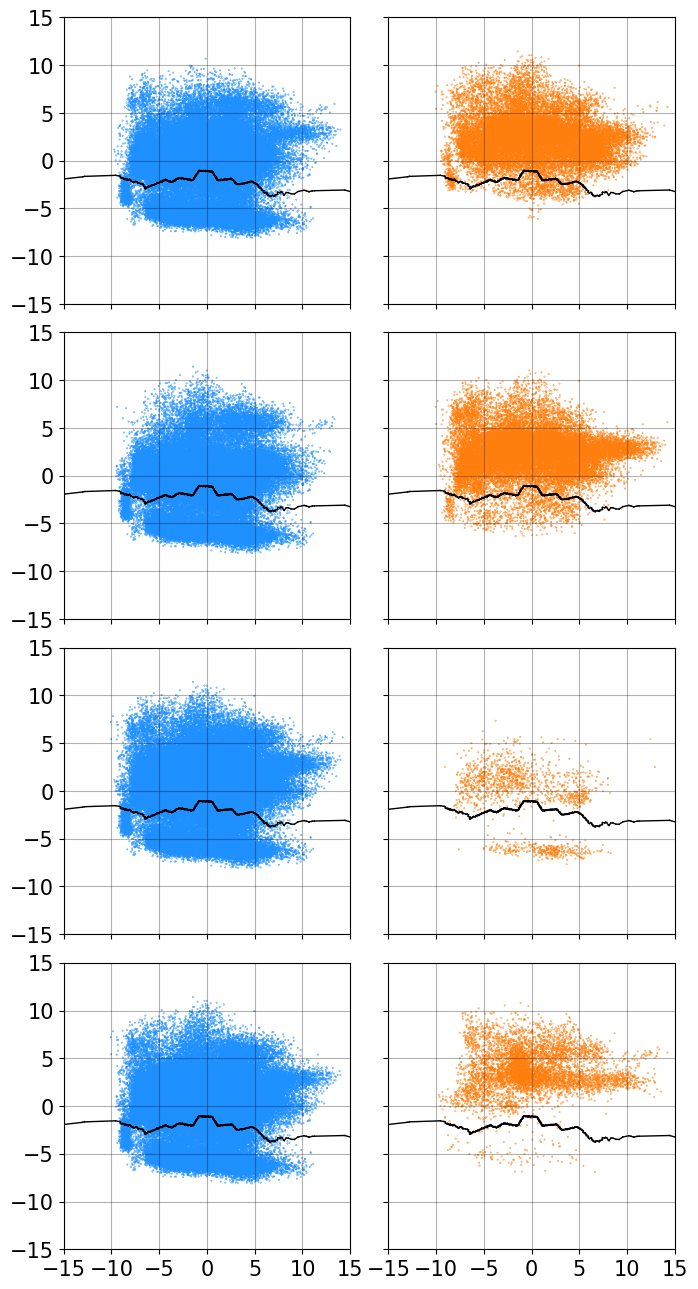

In [17]:
from sklearn.metrics import classification_report


fig, ax = plt.subplots(4, 2)
fig.set_size_inches(8, 16)
fig.subplots_adjust(hspace=0.1)
fig.subplots_adjust(wspace=0.1)


_, metastabled_trajs_concat, _ = compute_metastable_states(msm_models[n_clusters][lagtime], 2, np.concatenate(trajs), np.concatenate(clustered_trajs[n_clusters]))

base_buldges = np.concatenate(pickle.load(open(f"./pickle-cache/base-bulge/interactions.pickle", "rb"))).astype(int)

colors = ["#1E90FF", "tab:orange"]
trajs_concat = np.concatenate(trajs)

for residue_index_rna in range(4):
    ax[residue_index_rna, 0].scatter(trajs_concat[base_buldges[:,residue_index_rna]==0, 0], trajs_concat[base_buldges[:,residue_index_rna]==0, 1], c=[colors[state%2] for state in base_buldges[:,residue_index_rna] if state==0], s=0.1)
    ax[residue_index_rna, 1].scatter(trajs_concat[base_buldges[:,residue_index_rna]==1, 0], trajs_concat[base_buldges[:,residue_index_rna]==1, 1], c=[colors[state%2] for state in base_buldges[:,residue_index_rna] if state==1], s=0.1)
    # ax[residue_index_rna, 2].scatter(trajs_concat[:, 0], trajs_concat[:, 1], c=[colors[state%2] for state in base_buldges[:,residue_index_rna]], s=1)

    # print(classification_report(metastabled_trajs_concat, base_buldges[:,residue_index_rna]))
    
    _, _, boundary_lines = compute_metastable_states(msm_models[n_clusters][lagtime], 2, np.concatenate(trajs), np.concatenate(clustered_trajs[n_clusters]))
    plot_voronoi_boundary(ax[residue_index_rna, 0], boundary_lines)
    plot_voronoi_boundary(ax[residue_index_rna, 1], boundary_lines)
    # plot_voronoi_boundary(ax[residue_index_rna, 2], boundary_lines)
    
    for i_ax in range(2):
        ax[residue_index_rna, i_ax].set_xlim(-15, 15)
        ax[residue_index_rna, i_ax].set_ylim(-15, 15)
        ax[residue_index_rna, i_ax].set_xticks(range(-15, 16, 5))
        ax[residue_index_rna, i_ax].set_yticks(range(-15, 16, 5))
                
        ax[residue_index_rna, i_ax].grid(True, color="black", alpha=0.3)
        ax[residue_index_rna, i_ax].set_aspect("equal", adjustable="box")

for row in range(4):
    for column in range(2):
        if row == 3:
            ax[row, column].tick_params(axis="x", labelsize=15)
        else:
            ax[row, column].set_xticklabels([])

        if column == 0:
            ax[row, column].tick_params(axis="y", labelsize=15)
        else:
            ax[row, column].set_yticklabels([])

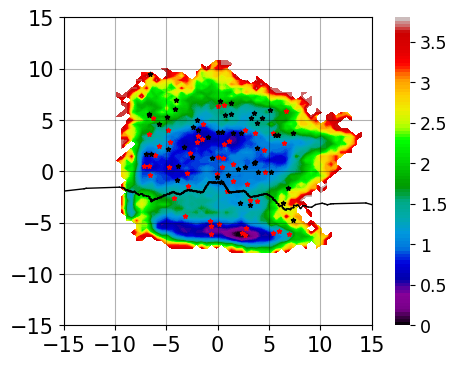

In [18]:
fig, ax = plt.subplots(1, 1)
fig.set_size_inches(6, 4)

energies, cbar = plot_energy_landscape(ax, msm_models[n_clusters][lagtime], trajs, clustered_trajs[n_clusters])
cbar.set_ticks(ticks=[0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5], labels=[0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5], size=12.5)

trajs_pacs_initial = np.array([pca.transform([_distances[0][0]])[0] for _distances in distances["pacs"]])
ax.scatter(*trajs_pacs_initial.transpose(1, 0), marker="*", s=10, color="red")

trajs_pacs_mean = np.array([pca.transform(np.concatenate(_distances)).mean(axis=0) for _distances in distances["pacs"]])
ax.scatter(*trajs_pacs_mean.transpose(1, 0), marker="*", s=10, color="black")

_, _, boundary_lines = compute_metastable_states(msm_models[n_clusters][lagtime], 2, np.concatenate(trajs), np.concatenate(clustered_trajs[n_clusters]))
plot_voronoi_boundary(ax, boundary_lines)


ax.set_xlim(-15, 15)
ax.set_ylim(-15, 15)
ax.set_xticks(range(-15, 16, 5))
ax.set_yticks(range(-15, 16, 5))
ax.tick_params(axis="x", labelsize=15)
ax.tick_params(axis="y", labelsize=15)